In [27]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from scipy.stats import linregress
import dask
import glob
import os
import seaborn as sns
from dask_jobqueue import PBSCluster
from dask.distributed import Client
import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42

In [219]:
ds_era5 = xr.open_dataset('/glade/derecho/scratch/adixit/India_Heatwave/review_comments/ERA5_analogs_distance_matrix.nc')['__xarray_dataarray_variable__'].load()
ds_era5_unf = xr.open_dataset('/glade/derecho/scratch/adixit/India_Heatwave/review_comments/ERA5-unforced_analogs_distance_matrix.nc')['__xarray_dataarray_variable__'].load()

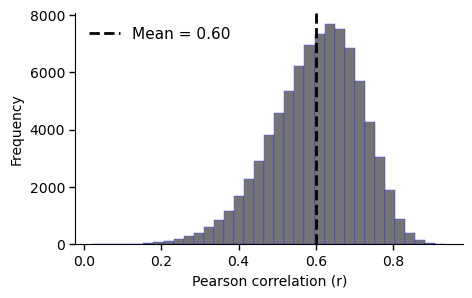

In [221]:
r = xr.corr(ds_era5, ds_era5_unf, dim='day').values.ravel()

fig, ax = plt.subplots(figsize=(5, 3))
ax.hist(r[np.isfinite(r)], bins=35, color='#737373', edgecolor='white', alpha=0.9)
ax.axvline(np.nanmean(r), color='#000000', ls='--', lw=2, label=f'Mean = {np.nanmean(r):.2f}')
ax.set(xlabel='Pearson correlation (r)', ylabel='Frequency')
ax.legend(frameon=False, fontsize=11)
ax.spines[['top', 'right']].set_visible(False)
ax.tick_params(direction='out', length=4, width=1)


n, bins, patches = ax.hist(r[np.isfinite(r)], bins=35, color='#737373', linewidth=0.25, alpha=0.9)

colors = plt.cm.viridis(np.linspace(0, 1, len(patches)))
for patch, color in zip(patches, colors):
    patch.set_edgecolor('b')
    
#plt.savefig("analog_verify_correlation.pdf",dpi=300,format='pdf',transparent=True)
plt.show()

In [207]:
ds_era5 = xr.open_dataset('/glade/derecho/scratch/adixit/India_Heatwave/review_comments/ERA5_analogs_distance_matrix.nc')['__xarray_dataarray_variable__'].load()
ds_era5_unf = xr.open_dataset('/glade/derecho/scratch/adixit/India_Heatwave/review_comments/ERA5-unforced_analogs_distance_matrix.nc')['__xarray_dataarray_variable__'].load()

In [208]:
era5 = ds_era5.values.reshape(123, 75, 74, 15).argmin(axis=-1)
era5_unf = ds_era5_unf.values.reshape(123, 75, 74, 15).argmin(axis=-1)

In [209]:
def align(M):
    F = np.full((123, 75, 75), -1, dtype=int)
    for y in range(75):
        F[:, y, np.arange(75) != y] = M[:, y, :]
    return F

era5,era5_unf = align(era5), align(era5_unf)
k = np.arange(15)

In [210]:
analog_sim = []
for t in k:
    analog_sim.append(np.mean(np.abs(era5-era5_unf)<=t)*100)

In [211]:
analog_sim

[24.87848238482385,
 44.51338753387534,
 53.631508581752485,
 60.87833785004517,
 67.1043179765131,
 72.52625112917795,
 77.28274616079494,
 81.54247515808491,
 85.29373080397471,
 88.64982836495031,
 91.64068654019873,
 94.17626016260162,
 96.35425474254743,
 98.1612285456188,
 100.0]

In [212]:
chance = (1 - (15-k-1)*(15-k)/15**2)*100

In [213]:
chance

array([  6.66666667,  19.11111111,  30.66666667,  41.33333333,
        51.11111111,  60.        ,  68.        ,  75.11111111,
        81.33333333,  86.66666667,  91.11111111,  94.66666667,
        97.33333333,  99.11111111, 100.        ])

In [214]:
null = []
for shift in range(1, 75):
    Bs = np.roll(B, shift, axis=1)
    mask = (A >= 0) & (Bs >= 0)
    null.append([(np.abs(A-Bs)[mask] <= t).mean()*100 for t in k])
null = np.round(np.array(null))

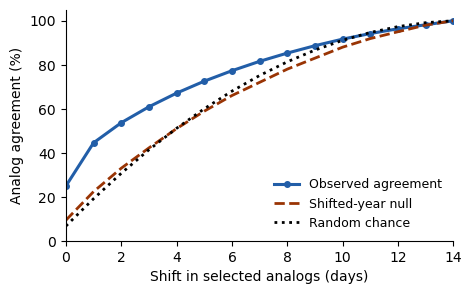

In [215]:

fig, ax = plt.subplots(figsize=(5, 3))

ax.plot(k, analog_sim, 'o-', color='#225ea8', lw=2.2, ms=4,label='Observed agreement')
ax.plot(k, null.mean(0), '--', color='#993404', lw=2,label='Shifted-year null')
ax.plot(k, chance, ':', color='black', lw=2,label='Random chance')

ax.set(xlabel='Shift in selected analogs (days)',ylabel='Analog agreement (%)', xlim=(0,14), ylim=(0,105))
ax.legend(frameon=False, fontsize=9)
ax.spines[['top','right']].set_visible(False)
ax.tick_params(direction='out')

plt.savefig('analog_shift_verify.pdf',dpi=300,format='pdf',transparent=True)
plt.show()



In [147]:
print(f'Exact agreement: {analog_sim[0]:.1f}%')
print(f'Within ±2 days: {analog_sim[2]:.1f}%')
print(f'Random chance: {chance[0]:.1f}%')

Exact agreement: 24.9%
Within ±2 days: 53.6%
Random chance: 7.0%
